# 04 – Time patterns and the chronological splits
Questions: how do volume and laundering change over time? Is the "no sender history" effect a warm-up artefact? Does hour of day matter? What is unusual about test_tail, and are the provisional split cutoffs reasonable?
Splits used: **all splits** for the timeline, split summary and tail analysis (description only, no modelling decisions); **train only** for the warm-up and hour-of-day analysis.

In [1]:
import sys
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "analysis").is_dir())
sys.path.insert(0, str(ROOT))

from src.analysis.data import load_eda_frame, load_timestamps, SPLIT_ORDER
from src.analysis.stats import rate_table, chi_square_test

pd.set_option("display.max_columns", 30)

everything = load_eda_frame(splits=SPLIT_ORDER).merge(load_timestamps(), on="transaction_id", how="left")
assert everything["timestamp"].notna().all(), "some transactions have no timestamp"
everything["date"] = everything["timestamp"].dt.floor("D")

cfg = json.loads((ROOT / "config" / "data.json").read_text())["split_boundaries"]
CUTOFFS = {
    name: pd.to_datetime(cfg[key], format="%Y/%m/%d %H:%M")
    for name, key in [("val starts", "train_cutoff"), ("test_main starts", "val_cutoff"), ("test_tail starts", "tail_cutoff")]
}
print(everything["timestamp"].min(), "→", everything["timestamp"].max())
CUTOFFS

2022-09-01 00:00:00 → 2022-09-18 16:18:00


{'val starts': Timestamp('2022-09-06 13:36:00'),
 'test_main starts': Timestamp('2022-09-08 16:12:00'),
 'test_tail starts': Timestamp('2022-09-11 00:00:00')}

In [2]:
summary = everything.groupby("split", observed=True).agg(
    start=("timestamp", "min"),
    end=("timestamp", "max"),
    transactions=("is_laundering", "size"),
    laundering=("is_laundering", "sum"),
    ach_share_pct=("payment_format", lambda s: round(100 * (s == "ACH").mean(), 2)),
)
summary["days_covered"] = ((summary["end"] - summary["start"]).dt.total_seconds() / 86400).round(2)
summary["rate_%"] = (100 * summary["laundering"] / summary["transactions"]).round(4)

ach = everything[everything["payment_format"] == "ACH"]
non_ach = everything[everything["payment_format"] != "ACH"]
summary["ach_rate_%"] = (100 * ach.groupby("split", observed=True)["is_laundering"].mean()).round(4)
summary["non_ach_rate_%"] = (100 * non_ach.groupby("split", observed=True)["is_laundering"].mean()).round(4)
summary

,start,end,transactions,laundering,ach_share_pct,days_covered,rate_%,ach_rate_%,non_ach_rate_%
split,,,,,,,,,
train,2022-09-01 00:00:00,2022-09-06 13:35:00,3046861,2297,11.11,5.57,0.0754,0.5625,0.0145
val,2022-09-06 13:36:00,2022-09-08 16:11:00,1015602,1082,12.10,2.11,0.1065,0.7519,0.0177
test_main,2022-09-08 16:12:00,2022-09-10 23:59:00,1014774,1143,13.61,2.32,0.1126,0.7232,0.0164
test_tail,2022-09-11 00:05:00,2022-09-18 16:18:00,1108,655,100.00,7.68,59.1155,59.1155,NaN


,transactions,laundering,rate_%
date,,,
2022-09-01,1114921,322,0.028881
2022-09-02,754449,408,0.054079
2022-09-03,207382,391,0.188541
2022-09-04,207430,407,0.196211
2022-09-05,482650,471,0.097586
2022-09-06,482089,531,0.110146
2022-09-07,482751,497,0.102952
2022-09-08,482773,539,0.111647
2022-09-09,654467,514,0.078537


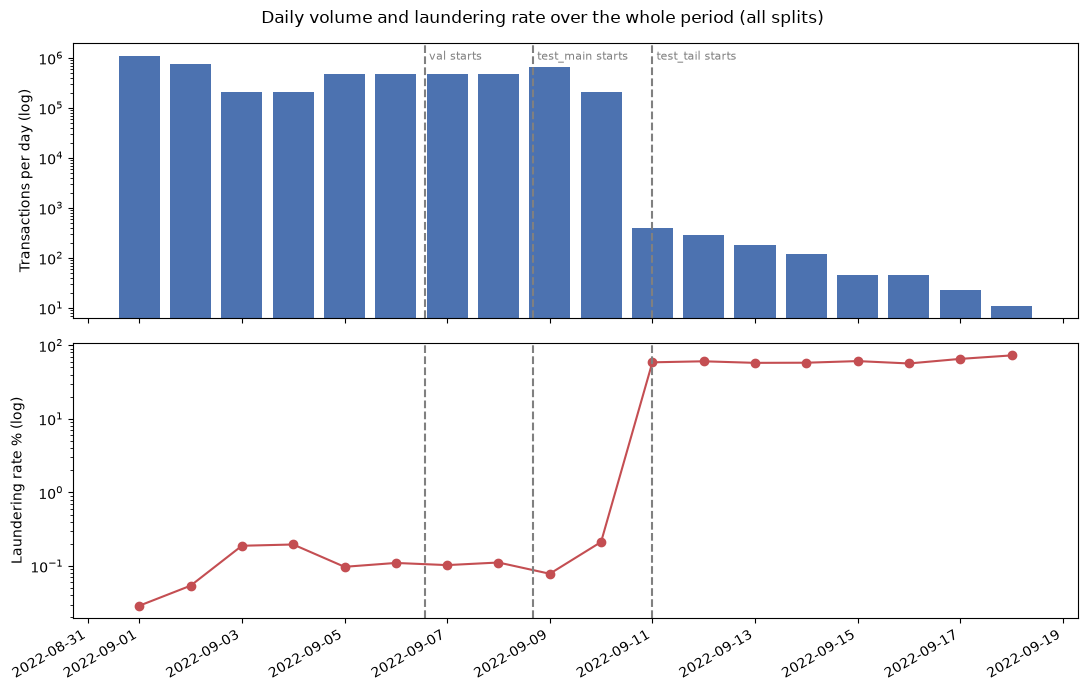

In [3]:
daily = everything.groupby("date").agg(
    transactions=("is_laundering", "size"), laundering=("is_laundering", "sum")
)
daily["rate_%"] = 100 * daily["laundering"] / daily["transactions"]
display(daily)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.bar(daily.index, daily["transactions"], width=0.8, color="#4C72B0")
ax1.set_yscale("log")
ax1.set_ylabel("Transactions per day (log)")
ax2.plot(daily.index, daily["rate_%"], marker="o", color="#C44E52")
ax2.set_yscale("log")
ax2.set_ylabel("Laundering rate % (log)")
for ax in (ax1, ax2):
    for when in CUTOFFS.values():
        ax.axvline(when, linestyle="--", color="grey")
for name, when in CUTOFFS.items():
    ax1.annotate(name, (when, 1), xycoords=("data", "axes fraction"), xytext=(3, -12),
                 textcoords="offset points", fontsize=8, color="grey")
fig.suptitle("Daily volume and laundering rate over the whole period (all splits)")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

In [4]:
train = everything[everything["split"] == "train"].copy()
start = train["timestamp"].min()

train["period"] = np.where(
    train["timestamp"] < start + pd.Timedelta(hours=24), "first 24h (warm-up)", "after first 24h"
)
train["sender_history"] = np.where(
    train["sender_txn_count_24h"] == 0, "no sender history", "has sender history"
)
warm = train.groupby(["period", "sender_history"]).agg(
    transactions=("is_laundering", "size"), laundering=("is_laundering", "sum")
)
warm["rate_%"] = (100 * warm["laundering"] / warm["transactions"]).round(4)
warm["share_of_period_%"] = (
    100 * warm["transactions"] / warm.groupby(level="period")["transactions"].transform("sum")
).round(1)
warm

transactions  laundering  rate_%  \
period              sender_history                                         
after first 24h     has sender history       1645325         995  0.0605   
                    no sender history         286615         980  0.3419   
first 24h (warm-up) has sender history        690658         269  0.0389   
                    no sender history         424263          53  0.0125   

                                        share_of_period_%  
period              sender_history                         
after first 24h     has sender history               85.2  
                    no sender history                14.8  
first 24h (warm-up) has sender history               61.9  
                    no sender history                38.1

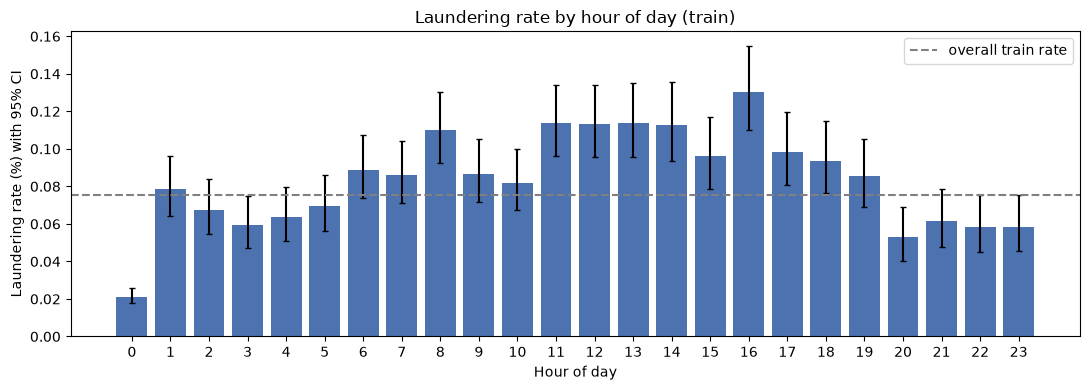

{'column': 'hour',
 'chi2': 391.1,
 'dof': 23,
 'p_value': 1.188652304224755e-68,
 'cramers_v': 0.0113,
 'min_expected_count': 74.9,
 'n': 3046861}

In [5]:
train["hour"] = train["timestamp"].dt.hour
hours = rate_table(train, "hour").sort_index()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(hours.index, hours["rate_%"], color="#4C72B0",
       yerr=[hours["rate_%"] - hours["ci_low_%"], hours["ci_high_%"] - hours["rate_%"]], capsize=2)
ax.axhline(100 * train["is_laundering"].mean(), linestyle="--", color="grey", label="overall train rate")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Laundering rate (%) with 95% CI")
ax.set_title("Laundering rate by hour of day (train)")
ax.legend()
fig.tight_layout()
plt.show()

chi_square_test(train, "hour")

In [6]:
tail = everything[everything["split"] == "test_tail"]
print("Payment formats in test_tail:")
print(tail["payment_format"].value_counts()[lambda s: s > 0])

tail_daily = tail.groupby("date").agg(
    transactions=("is_laundering", "size"), laundering=("is_laundering", "sum")
)
tail_daily["rate_%"] = (100 * tail_daily["laundering"] / tail_daily["transactions"]).round(2)
display(tail_daily)

main_ach = everything[(everything["split"] == "test_main") & (everything["payment_format"] == "ACH")]
compare = pd.DataFrame(
    {
        "test_main ACH": [len(main_ach), 100 * main_ach["is_laundering"].mean(),
                          main_ach["log_amount_paid"].median(), 100 * main_ach["same_bank"].mean(),
                          main_ach["sender_txn_count_24h"].median()],
        "test_tail (all ACH)": [len(tail), 100 * tail["is_laundering"].mean(),
                                tail["log_amount_paid"].median(), 100 * tail["same_bank"].mean(),
                                tail["sender_txn_count_24h"].median()],
    },
    index=["transactions", "laundering rate %", "median log amount", "same bank %", "median sender 24h count"],
).round(3)
compare

Payment formats in test_tail:
payment_format
ACH    1108
Name: count, dtype: int64


,transactions,laundering,rate_%
date,,,
2022-09-11,396,232,58.59
2022-09-12,281,170,60.50
2022-09-13,184,106,57.61
2022-09-14,121,70,57.85
2022-09-15,46,28,60.87
2022-09-16,46,26,56.52
2022-09-17,23,15,65.22
2022-09-18,11,8,72.73


,test_main ACH,test_tail (all ACH)
transactions,138141.000,1108.000
laundering rate %,0.723,59.116
median log amount,7.346,9.470
same bank %,13.389,37.365
median sender 24h count,2.000,0.000


## What I found
**Timeline (all splits)**
- The data has a weekly cycle (1 Sept 2022 was a Thursday): weekend days (3, 4 and 10 Sept) have ≈207k transactions vs ≈480k on weekdays.
- The number of laundering transactions stays roughly constant (≈320–540 per day), so the laundering rate roughly doubles at weekends (0.19–0.21% vs ≈0.10–0.11%).
- 1–2 Sept have the highest volume (1.1M and 754k) and the lowest rates (0.03% and 0.05%), which looks like a start-up burst of legitimate activity.
- Normal activity ends on 10 Sept. From 11–18 Sept volume falls from 396 to 11 transactions per day while the laundering rate stays at 57–73% every day.

**Warm-up check (train)**
- The "no sender history" effect is real, not a warm-up artefact. After the first 24 hours, senders with no outgoing payments in the previous 24h launder at 0.34% vs 0.061% for senders with history (≈5.7×), and they account for 980 of 2,297 train laundering transactions (43%).
- The warm-up day dilutes rather than creates this effect: during it, many legitimate senders also have empty histories (0.013%).

**Hour of day (train)**
- Laundering is more common during working hours (≈0.11–0.13% at 11:00–16:00) and rare at 00:00 (0.021%). The pattern is statistically significant (χ² = 391, df = 23, p < 0.001) but weak (Cramér's V = 0.011). Time is not a model feature.

**test_tail**
- All 1,108 test_tail transactions are ACH. Compared with ACH in test_main they have much larger amounts (median log amount 9.47 vs 7.35), more same-bank payments (37% vs 13%) and empty sender histories (median 24h count 0 vs 2).
- This is consistent with the simulator's unfinished laundering activity after normal activity stopped. Feature distributions there differ strongly from the rest of the data, which supports reporting test_main separately from the combined test view.

**Split cutoffs (evidence for approval)**
- The cutoffs give a chronological 60/20/20 split by rows.
- Val and test_main are similar (laundering rate 0.107% vs 0.113%; ACH share 12.1% vs 13.6%; ACH laundering rate 0.75% vs 0.72%), which suits tuning on val and testing on test_main.
- Train has a lower laundering rate (0.075%; ACH rate 0.56%), partly because it contains the low-rate start-up days 1–2 Sept. The weekday mix also differs: train contains one weekend, val none, and test_main ends on a Saturday. Neither requires changing the cutoffs, but both should be noted in the report.